<a href="https://colab.research.google.com/github/tejas883/Roll_No_32_Machine-Learning-Lab/blob/main/ML_Experiment_10_DBSCAN_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#  ML Experiment Number 10

Student Name : Tejas Surendra Mule


Batch : CS 02


Roll Number : CS32



### **Aim**

To implement DBSCAN clustering using Python for customer segmentation on the Mall Customer Segmentation dataset and identify arbitrary-shaped clusters along with spatial outliers (noise).

## Objectives

1. To understand the principles of Density-Based Spatial Clustering of Applications with Noise (DBSCAN).
2. To implement DBSCAN clustering using Python.3. To preprocess and feature-scale tabular customer data using StandardScaler.
4. To determine optimal hyperparameters ($\varepsilon$ and $min\_samples$) using $k$-distance graph analysis.
5. To identify core points, border points, and spatial outliers (noise points denoted by label $-1$).
6. To evaluate clustering performance using metrics like Silhouette Score.

# Relevant Theory

###DBSCAN (Density-Based Spatial Clustering of Applications with Noise)
DBSCAN is an unsupervised non-parametric clustering algorithm that groups data points based on local density estimations. Unlike centroid-based algorithms (e.g., K-Means), DBSCAN can discover arbitrary-shaped clusters and automatically isolate noisy data points without requiring the user to specify the total number of clusters in advance.

Core Concepts and Parameters:

1. $\varepsilon$ (Epsilon): The maximum radius of the neighborhood around a given data point $x$.
2. $min\_samples$ (MinPts): The minimum number of points within the $\varepsilon$-neighborhood required to form a dense region.

Point ClassificationsCore Point:
* A point that has at least $min\_samples$ within its $\varepsilon$-neighborhood.
* Border Point: A point that is within the $\varepsilon$-neighborhood of a Core Point but has fewer than $min\_samples$ in its own neighborhood.
* Noise Point (Outlier): A point that is neither a Core Point nor a Border Point. Noise points are assigned a cluster label of $-1$.

###Dataset Information
Get the Mall Customer Segmentation dataset from Kaggle using the following link:
https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python

The dataset contains spending patterns and demographic attributes of mall customers:

* CustomerID: Unique identifier for each customer.

* Gender: Male or Female.

* Age: Age of the customer.

* Annual Income (k$): Annual income of the customer in thousands of dollars.

* Spending Score (1-100): Score assigned based on customer behavior and purchasing patterns.

For clustering, we will use: Annual Income (k$) and Spending Score (1-100).

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Mall Customer Segmentation dataset (Mall_Customers.csv).
---

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

df = pd.read_csv("Mall_Customers.csv")
print("Dataset shape:", df.shape)
print("Missing values:", int(df.isnull().sum().sum()))
df.head()

Dataset shape: (200, 5)
Missing values: 0


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


# Task 2: Feature Selection and Standardization

* Select target features (Annual Income ($k$) and Spending Score (1-100)).
* Scale features using Standard Scaler to bring feature dimensions to a comparable range ($\mu=0, \sigma=1$), which is crucial for distance-based neighborhood computations.

In [ ]:
features = ["Annual Income (k$)", "Spending Score (1-100)"]
X = df[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled data shape:", X_scaled.shape)
print("Means :", X_scaled.mean(axis=0).round(6))
print("Std   :", X_scaled.std(axis=0).round(6))

Scaled data shape: (200, 2)
Means : [-0. -0.]
Std   : [1. 1.]


# Task 3: Hyperparameter Selection via $k$-Distance Graph

* Compute Nearest Neighbors using NearestNeighbors ($k = min\_samples$).
* Plot sorted $k$-distances to locate the "elbow point," which indicates the optimal value for $\varepsilon$ (Epsilon).

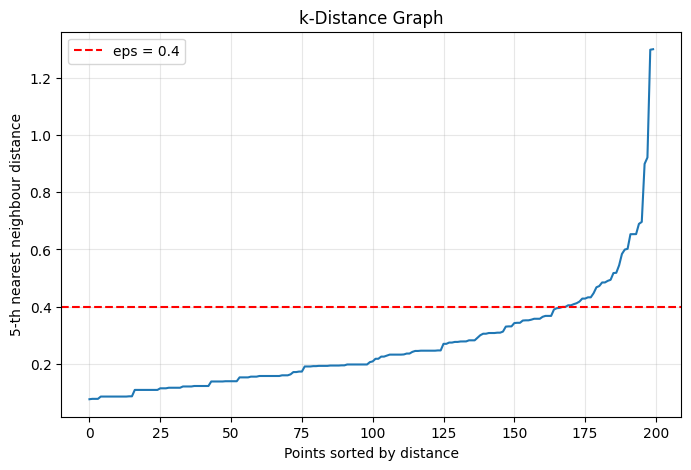

Selected eps        : 0.4
Selected min_samples: 5


In [ ]:
min_samples = 5          # DBSCAN default; a point counts itself as one of its neighbours

# Distance of every point to its min_samples-th nearest neighbour
neighbors = NearestNeighbors(n_neighbors=min_samples).fit(X_scaled)
distances, _ = neighbors.kneighbors(X_scaled)
k_distances = np.sort(distances[:, -1])

# eps chosen at the "elbow" where the sorted curve starts rising steeply
eps = 0.4

plt.figure(figsize=(8, 5))
plt.plot(k_distances)
plt.axhline(eps, color="red", linestyle="--", label=f"eps = {eps}")
plt.xlabel("Points sorted by distance")
plt.ylabel(f"{min_samples}-th nearest neighbour distance")
plt.title("k-Distance Graph")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Selected eps        :", eps)
print("Selected min_samples:", min_samples)

# Task 4: Implement DBSCAN Clustering

* Instantiate sklearn.cluster.DBSCAN with the identified $\varepsilon$ and $min\_samples$.
* Fit the model on scaled data to generate cluster assignments and noise labels ($-1$).

In [ ]:
dbscan = DBSCAN(eps=eps, min_samples=min_samples)
labels = dbscan.fit_predict(X_scaled)

print("Cluster labels found:", [int(l) for l in sorted(set(labels))])
print("Points per label    :", {int(k): int(v) for k, v in zip(*np.unique(labels, return_counts=True))})

Cluster labels found: [-1, 0, 1, 2, 3]
Points per label    : {-1: 15, 0: 115, 1: 11, 2: 32, 3: 27}


# Task 5: Evaluate DBSCAN Clustering

* Cluster Count: Calculate the number of clusters generated (excluding noise points).
* Noise Point Analysis: Count and evaluate identified spatial outliers (label $-1$).
* Silhouette Score: Calculate Silhouette Score to evaluate cluster cohesion and separation.

In [ ]:
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = int((labels == -1).sum())

# Core / border / noise points
core_mask = np.zeros(len(labels), dtype=bool)
core_mask[dbscan.core_sample_indices_] = True
n_core = int(core_mask.sum())
n_border = int(((~core_mask) & (labels != -1)).sum())

print("Number of clusters (excluding noise):", n_clusters)
print("Core points  :", n_core)
print("Border points:", n_border)
print(f"Noise points : {n_noise} ({n_noise / len(labels) * 100:.1f}% of all customers)")

# Silhouette score is computed on clustered points only (noise has no cluster)
mask = labels != -1
sil = silhouette_score(X_scaled[mask], labels[mask])
print(f"\nSilhouette Score (noise excluded): {sil:.4f}")

Number of clusters (excluding noise): 4
Core points  : 169
Border points: 16
Noise points : 15 (7.5% of all customers)

Silhouette Score (noise excluded): 0.4781


# Task 6: Analyze Results and Cluster Statistics
* Extract cluster labels and append them back to the original dataset.

* Calculate mean statistics (e.g., average Annual Income and Spending Score) per cluster to interpret final customer segments and evaluate detected noise points.

Cluster summary (Cluster -1 = noise):


,Customers,Avg_Annual_Income,Avg_Spending_Score
Cluster,,,
-1,15,96.13,61.80
0,115,48.30,51.73
1,11,23.73,8.91
2,32,80.88,83.62
3,27,83.93,14.44


Noise points:


,CustomerID,Annual Income (k$),Spending Score (1-100)
7,8,18,94
11,12,19,99
19,20,23,98
169,170,87,63
184,185,99,39
187,188,101,68
191,192,103,69
192,193,113,8
193,194,113,91
194,195,120,16


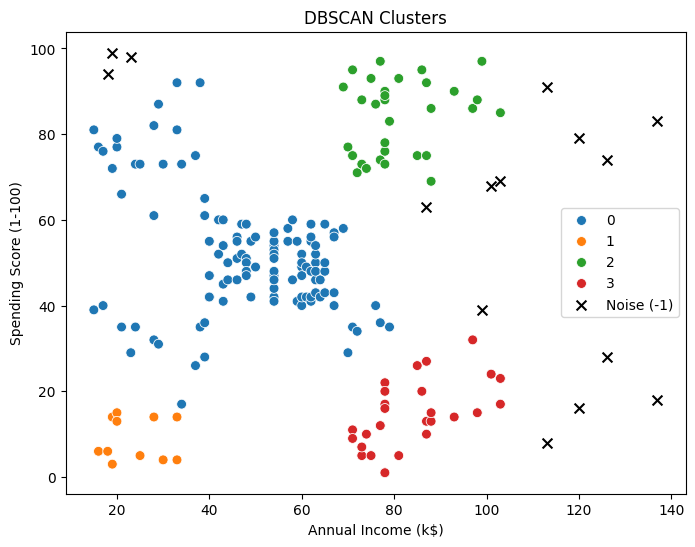

In [ ]:
df["Cluster"] = labels

summary = df.groupby("Cluster").agg(
    Customers=("CustomerID", "count"),
    Avg_Annual_Income=("Annual Income (k$)", "mean"),
    Avg_Spending_Score=("Spending Score (1-100)", "mean"),
).round(2)
print("Cluster summary (Cluster -1 = noise):")
display(summary)

print("Noise points:")
display(df[df["Cluster"] == -1][["CustomerID", "Annual Income (k$)", "Spending Score (1-100)"]])

plt.figure(figsize=(8, 6))
sns.scatterplot(data=df[df["Cluster"] != -1], x="Annual Income (k$)", y="Spending Score (1-100)",
                hue="Cluster", palette="tab10", s=50)
plt.scatter(df.loc[df["Cluster"] == -1, "Annual Income (k$)"],
            df.loc[df["Cluster"] == -1, "Spending Score (1-100)"],
            color="black", marker="x", s=50, label="Noise (-1)")
plt.title("DBSCAN Clusters")
plt.legend()
plt.show()

# Conclusion

The experiment successfully implemented DBSCAN clustering on the Mall Customer Segmentation dataset. Feature standardization ensured balanced neighborhood distance calculations across income and spending metrics. By analyzing $k$-distance graphs, optimal $\varepsilon$ and $min\_samples$ parameters were selected, enabling the discovery of density-defined customer segments and explicit identification of spatial noise points (outliers) without requiring a pre-defined cluster count.